In [1]:
import sys; sys.path.insert(0, "../src")
import numpy as np, matplotlib.pyplot as plt
import forecast as F
from sklearn.tree import DecisionTreeRegressor, export_text

In [2]:
df = F.load_all(); X = F.make_features(df); y = df["demand"]
ok = X.notna().all(axis=1); X, y = X[ok], y[ok]
train = X.index < F.TEST_START
feats = F.CALENDAR + F.LAGS + F.WEATHER

In [6]:
# 1. A single readable tree: try max_depth 2, 3, 5
t = DecisionTreeRegressor(max_depth=3, min_samples_leaf=40).fit(X.loc[train, feats], y[train])
print(export_text(t, feature_names=feats))

|--- demand_lag_7d <= 28058.50
|   |--- demand_lag_7d <= 22040.50
|   |   |--- demand_lag_7d <= 19580.50
|   |   |   |--- value: [18974.51]
|   |   |--- demand_lag_7d >  19580.50
|   |   |   |--- value: [21318.97]
|   |--- demand_lag_7d >  22040.50
|   |   |--- demand_lag_7d <= 25286.50
|   |   |   |--- value: [23849.57]
|   |   |--- demand_lag_7d >  25286.50
|   |   |   |--- value: [26179.07]
|--- demand_lag_7d >  28058.50
|   |--- demand_lag_7d <= 32539.50
|   |   |--- demand_lag_2d <= 30274.00
|   |   |   |--- value: [28587.09]
|   |   |--- demand_lag_2d >  30274.00
|   |   |   |--- value: [31679.36]
|   |--- demand_lag_7d >  32539.50
|   |   |--- temperature <= 6.84
|   |   |   |--- value: [37474.04]
|   |   |--- temperature >  6.84
|   |   |   |--- value: [33296.08]



Text(0, 0.5, 'validation MAE (MW)')

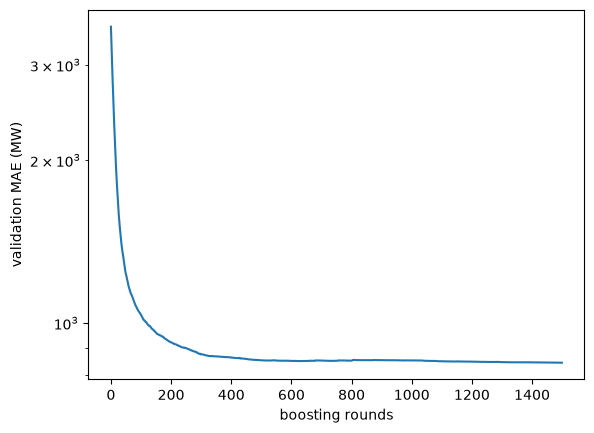

In [8]:
# 2. The learning curve: validation error after each round
tr, va = X.index < F.VAL_START, (X.index >= F.VAL_START) & train
m = F.fit(X.loc[tr, feats], y[tr], 1500)
curve = [np.abs(y[va] - p).mean() for p in m.staged_predict(X.loc[va, feats])]
plt.semilogy(curve); plt.xlabel("boosting rounds"); plt.ylabel("validation MAE (MW)")

In [9]:
# 3. No extrapolation: vary temperature for one winter half-hour
m = F.fit(X.loc[train, feats], y[train], 1455)
row = X.loc[train, feats].iloc[[1000]].copy()
for T in [-15, -8, -3, 0, 5, 10]:
    r = row.copy(); r["temperature"] = T; r["temperature_24h"] = T
    print(T, m.predict(r)[0])

-15 37027.498520857815
-8 37027.498520857815
-3 37027.498520857815
0 36805.73103808388
5 34510.99283515388
10 32457.634574177686
